<a href="https://colab.research.google.com/github/rashidkhan-dev0101/BreastVision_Ai/blob/main/BreastVision_AI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip -q install kagglehub

In [2]:
import kagglehub
from pathlib import Path

path = kagglehub.dataset_download(
    "aryashah2k/breast-ultrasound-images-dataset"
)

DATA_ROOT = Path(path)

print("Dataset downloaded to:", DATA_ROOT)

100%|██████████| 195M/195M [00:01<00:00, 129MB/s]

Extracting files...


Dataset downloaded to: /root/.cache/kagglehub/datasets/aryashah2k/breast-ultrasound-images-dataset/versions/1


In [3]:
import os

for root, dirs, files in os.walk(DATA_ROOT):
    depth = root.replace(str(DATA_ROOT), "").count(os.sep)

    if depth <= 3:
        print("  " * depth + os.path.basename(root) + "/")

        for filename in files[:5]:
            print("  " * (depth + 1) + filename)

1/
  Dataset_BUSI_with_GT/
    benign/
      benign (100)_mask.png
      benign (232).png
      benign (78).png
      benign (371)_mask.png
      benign (329)_mask.png
    normal/
      normal (33).png
      normal (108).png
      normal (113)_mask.png
      normal (115)_mask.png
      normal (44).png
    malignant/
      malignant (26)_mask.png
      malignant (103).png
      malignant (179).png
      malignant (202)_mask.png
      malignant (66)_mask.png


In [4]:
import os
import random
import copy
import hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, roc_auc_score,
    roc_curve, precision_recall_curve,
    classification_report
)
from sklearn.utils.class_weight import compute_class_weight

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch:", torch.__version__)
print("Device:", device)
print("Dataset path:", DATA_ROOT)
print("Dataset path exists:", Path(DATA_ROOT).exists())

PyTorch: 2.11.0+cpu
Device: cpu
Dataset path: /root/.cache/kagglehub/datasets/aryashah2k/breast-ultrasound-images-dataset/versions/1
Dataset path exists: True


In [5]:
DATA_ROOT = Path(DATA_ROOT)

class_dirs = {}

for label in ["benign", "malignant", "normal"]:
    matches = [
        p for p in DATA_ROOT.rglob(label)
        if p.is_dir() and p.name.lower() == label
    ]

    if matches:
        class_dirs[label] = matches[0]

print("Found folders:")
for label, folder in class_dirs.items():
    print(label, "->", folder)

assert len(class_dirs) == 3, (
    "Could not find all three class folders. "
    "Check your Step C folder output."
)

records = []

for label, folder in class_dirs.items():
    for path in folder.rglob("*"):
        if not path.is_file():
            continue

        if path.suffix.lower() not in [".png", ".jpg", ".jpeg"]:
            continue

        # Exclude masks from classification
        if "_mask" in path.stem.lower():
            continue

        records.append({
            "path": str(path),
            "label": label,
            "filename": path.name
        })

df = pd.DataFrame(records)

print("\nTotal original images:", len(df))
print("\nImages per class:")
print(df["label"].value_counts())

display(df.head())

Found folders:
benign -> /root/.cache/kagglehub/datasets/aryashah2k/breast-ultrasound-images-dataset/versions/1/Dataset_BUSI_with_GT/benign
malignant -> /root/.cache/kagglehub/datasets/aryashah2k/breast-ultrasound-images-dataset/versions/1/Dataset_BUSI_with_GT/malignant
normal -> /root/.cache/kagglehub/datasets/aryashah2k/breast-ultrasound-images-dataset/versions/1/Dataset_BUSI_with_GT/normal

Total original images: 780

Images per class:
label
benign       437
malignant    210
normal       133
Name: count, dtype: int64


,path,label,filename
0,/root/.cache/kagglehub/datasets/aryashah2k/bre...,benign,benign (232).png
1,/root/.cache/kagglehub/datasets/aryashah2k/bre...,benign,benign (78).png
2,/root/.cache/kagglehub/datasets/aryashah2k/bre...,benign,benign (105).png
3,/root/.cache/kagglehub/datasets/aryashah2k/bre...,benign,benign (119).png
4,/root/.cache/kagglehub/datasets/aryashah2k/bre...,benign,benign (243).png


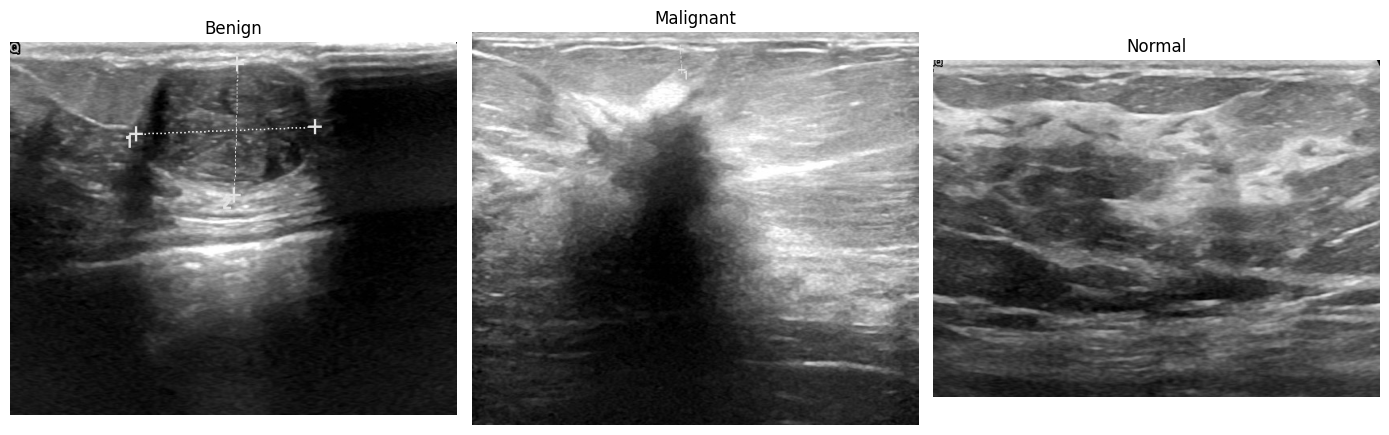

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 5))

for ax, label in zip(axes, ["benign", "malignant", "normal"]):
    samples = df[df["label"] == label]

    if samples.empty:
        ax.set_title(f"No images: {label}")
        ax.axis("off")
        continue

    row = samples.iloc[0]
    image = Image.open(row["path"]).convert("RGB")

    ax.imshow(image)
    ax.set_title(label.capitalize())
    ax.axis("off")

plt.tight_layout()
plt.show()

             width      height  aspect_ratio    gray_min    gray_max
count   780.000000  780.000000    780.000000  780.000000  780.000000
mean    615.679487  501.452564      1.229399    0.216667  251.987179
std     122.055701   76.687948      0.166526    1.671471    7.786123
min     190.000000  310.000000      0.567164    0.000000  207.000000
25%     554.000000  465.000000      1.171859    0.000000  255.000000
50%     564.000000  474.000000      1.198276    0.000000  255.000000
75%     713.500000  574.000000      1.316645    0.000000  255.000000
max    1048.000000  719.000000      2.052632   22.000000  255.000000


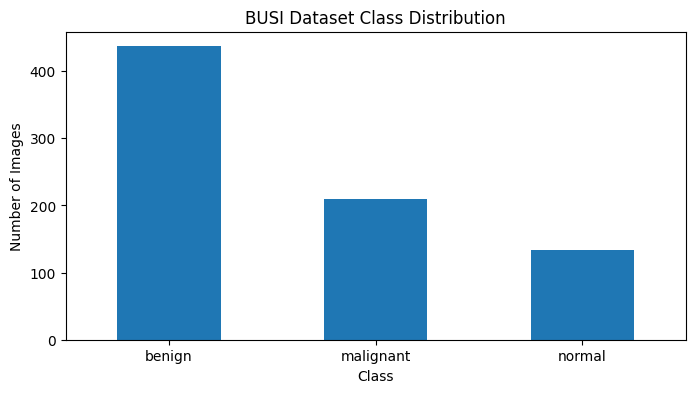


Image dimensions:
                width      height
label                            
benign     613.386728  495.471396
malignant  597.971429  494.014286
normal     651.172932  532.849624


In [7]:
dimensions = []

for _, row in df.iterrows():
    with Image.open(row["path"]) as img:
        width, height = img.size
        pixel_range = img.convert("L").getextrema()

    dimensions.append({
        "width": width,
        "height": height,
        "aspect_ratio": width / height,
        "gray_min": pixel_range[0],
        "gray_max": pixel_range[1]
    })

eda_df = pd.concat(
    [df.reset_index(drop=True), pd.DataFrame(dimensions)],
    axis=1
)

print(eda_df[[
    "width", "height", "aspect_ratio", "gray_min", "gray_max"
]].describe())

eda_df["label"].value_counts().plot(
    kind="bar", figsize=(8, 4)
)

plt.title("BUSI Dataset Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=0)
plt.show()

print("\nImage dimensions:")
print(eda_df.groupby("label")[["width", "height"]].mean())

In [8]:
lesion_df = eda_df[
    eda_df["label"].isin(["benign", "malignant"])
].copy()

lesion_df["target"] = lesion_df["label"].map({
    "benign": 0,
    "malignant": 1
})

# Detect exact duplicate files by file content
def get_sha256(path):
    with open(path, "rb") as f:
        return hashlib.sha256(f.read()).hexdigest()

lesion_df["sha256"] = lesion_df["path"].apply(get_sha256)

print("Before exact-duplicate removal:", len(lesion_df))

lesion_df = lesion_df.drop_duplicates(
    subset="sha256"
).reset_index(drop=True)

print("After exact-duplicate removal:", len(lesion_df))
print(lesion_df["label"].value_counts())

Before exact-duplicate removal: 647
After exact-duplicate removal: 646
label
benign       437
malignant    209
Name: count, dtype: int64


In [9]:
train_df, temp_df = train_test_split(
    lesion_df,
    test_size=0.30,
    random_state=SEED,
    stratify=lesion_df["target"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_df["target"]
)

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

for name, part in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(f"\n{name} class counts:")
    print(part["label"].value_counts())

Training images: 452
Validation images: 97
Testing images: 97

Train class counts:
label
benign       306
malignant    146
Name: count, dtype: int64

Validation class counts:
label
benign       65
malignant    32
Name: count, dtype: int64

Test class counts:
label
benign       66
malignant    31
Name: count, dtype: int64


In [10]:
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(contrast=0.15),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

class BreastDataset(Dataset):
    def __init__(self, dataframe, transform):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        image = Image.open(row["path"]).convert("RGB")
        image = self.transform(image)

        label = torch.tensor(
            int(row["target"]), dtype=torch.long
        )

        return image, label

train_ds = BreastDataset(train_df, train_transform)
val_ds = BreastDataset(val_df, eval_transform)
test_ds = BreastDataset(test_df, eval_transform)

train_loader = DataLoader(
    train_ds, batch_size=16, shuffle=True, num_workers=2
)
val_loader = DataLoader(
    val_ds, batch_size=16, shuffle=False, num_workers=2
)
test_loader = DataLoader(
    test_ds, batch_size=16, shuffle=False, num_workers=2
)

images, labels = next(iter(train_loader))
print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)

Image batch shape: torch.Size([16, 3, 224, 224])
Label batch shape: torch.Size([16])


In [11]:
class BaselineCNN(nn.Module):
    def __init__(self):
        super().__init__()

        layers = []
        channels = [3, 32, 64, 128, 256]

        for i in range(4):
            layers.extend([
                nn.Conv2d(
                    channels[i], channels[i + 1],
                    kernel_size=3, padding=1, bias=False
                ),
                nn.BatchNorm2d(channels[i + 1]),
                nn.ReLU(inplace=True),
                nn.MaxPool2d(2),
                nn.Dropout2d(0.15)
            ])

        self.features = nn.Sequential(*layers)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(128, 2)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x)
        return self.classifier(x)

baseline = BaselineCNN().to(device)

print(baseline)

BaselineCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Dropout2d(p=0.15, inplace=False)
    (5): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (6): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (7): ReLU(inplace=True)
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): Dropout2d(p=0.15, inplace=False)
    (10): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (11): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (12): ReLU(inplace=True)
    (13): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (14)

In [12]:
def build_model(name, freeze=True):
    if name == "resnet50":
        model = models.resnet50(
            weights=models.ResNet50_Weights.DEFAULT
        )

        if freeze:
            for p in model.parameters():
                p.requires_grad = False

        model.fc = nn.Linear(model.fc.in_features, 2)

    elif name == "efficientnet_b0":
        model = models.efficientnet_b0(
            weights=models.EfficientNet_B0_Weights.DEFAULT
        )

        if freeze:
            for p in model.parameters():
                p.requires_grad = False

        in_features = model.classifier[1].in_features
        model.classifier[1] = nn.Linear(in_features, 2)

    else:
        raise ValueError("Unsupported model name")

    return model.to(device)

resnet = build_model("resnet50", freeze=True)
efficientnet = build_model("efficientnet_b0", freeze=True)

print("Both pretrained models are ready.")

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 133MB/s]


Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 99.9MB/s]

Both pretrained models are ready.


In [13]:
class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.array([0, 1]),
    y=train_df["target"].values
)

criterion = nn.CrossEntropyLoss(
    weight=torch.tensor(
        class_weights, dtype=torch.float32, device=device
    )
)

def run_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)

    total_loss = 0.0
    correct = 0
    total = 0

    for x, y in loader:
        x, y = x.to(device), y.to(device)

        if training:
            optimizer.zero_grad()

        with torch.set_grad_enabled(training):
            logits = model(x)
            loss = criterion(logits, y)

            if training:
                loss.backward()
                optimizer.step()

        total_loss += loss.item() * y.size(0)
        correct += (logits.argmax(1) == y).sum().item()
        total += y.size(0)

    return total_loss / total, correct / total


def train_model(model, name, epochs=8, lr=1e-3):
    optimizer = torch.optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=lr,
        weight_decay=1e-4
    )

    history = {
        "train_loss": [], "val_loss": [],
        "train_acc": [], "val_acc": []
    }

    best_val_loss = float("inf")
    best_state = copy.deepcopy(model.state_dict())

    for epoch in range(epochs):
        train_loss, train_acc = run_epoch(
            model, train_loader, optimizer
        )
        val_loss, val_acc = run_epoch(model, val_loader)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        print(
            f"{name} | Epoch {epoch+1}/{epochs} | "
            f"Train loss: {train_loss:.4f} | "
            f"Val loss: {val_loss:.4f} | "
            f"Val accuracy: {val_acc:.4f}"
        )

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())

    model.load_state_dict(best_state)
    torch.save(model.state_dict(), f"{name}.pth")

    return model, history


baseline, hist_cnn = train_model(
    baseline, "baseline_cnn", epochs=8, lr=1e-3
)

resnet, hist_resnet = train_model(
    resnet, "resnet50_frozen", epochs=8, lr=1e-3
)

efficientnet, hist_eff = train_model(
    efficientnet, "efficientnet_b0_frozen", epochs=8, lr=1e-3
)

baseline_cnn | Epoch 1/8 | Train loss: 0.7151 | Val loss: 0.6872 | Val accuracy: 0.3299
baseline_cnn | Epoch 2/8 | Train loss: 0.6844 | Val loss: 0.6562 | Val accuracy: 0.4433
baseline_cnn | Epoch 3/8 | Train loss: 0.6562 | Val loss: 0.6023 | Val accuracy: 0.6495
baseline_cnn | Epoch 4/8 | Train loss: 0.6594 | Val loss: 0.5929 | Val accuracy: 0.6392
baseline_cnn | Epoch 5/8 | Train loss: 0.6548 | Val loss: 0.5985 | Val accuracy: 0.6804
baseline_cnn | Epoch 6/8 | Train loss: 0.6690 | Val loss: 0.5803 | Val accuracy: 0.7320
baseline_cnn | Epoch 7/8 | Train loss: 0.6439 | Val loss: 0.5743 | Val accuracy: 0.6598
baseline_cnn | Epoch 8/8 | Train loss: 0.6497 | Val loss: 0.5984 | Val accuracy: 0.6186
resnet50_frozen | Epoch 1/8 | Train loss: 0.6721 | Val loss: 0.6632 | Val accuracy: 0.7113
resnet50_frozen | Epoch 2/8 | Train loss: 0.6519 | Val loss: 0.6399 | Val accuracy: 0.7010
resnet50_frozen | Epoch 3/8 | Train loss: 0.5639 | Val loss: 0.6033 | Val accuracy: 0.7010
resnet50_frozen | Epoch

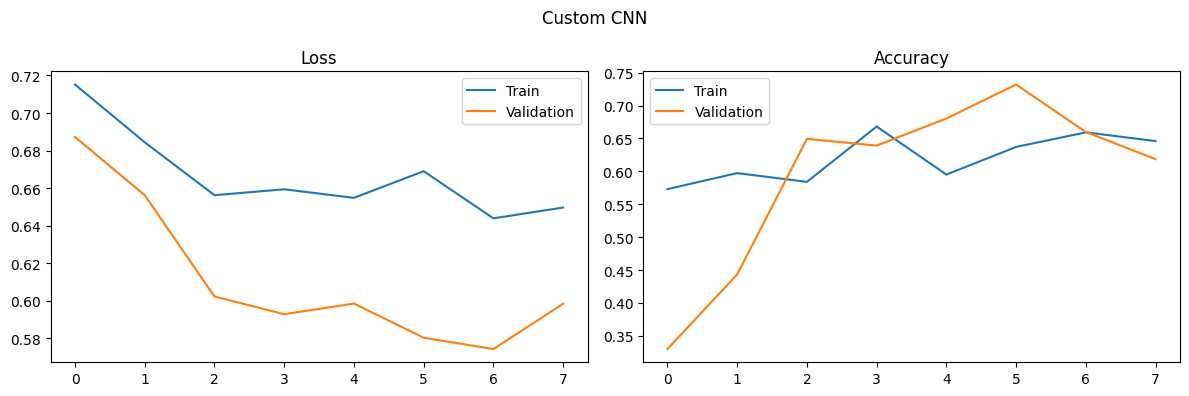

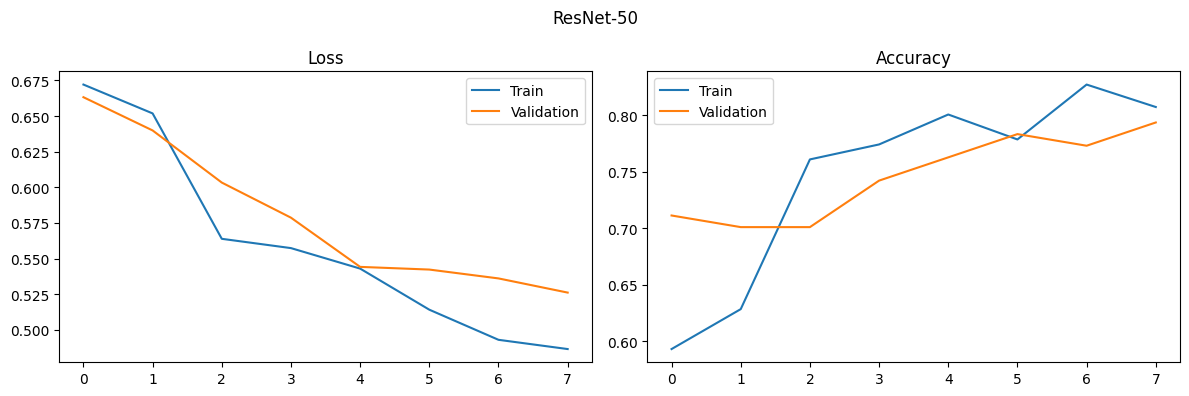

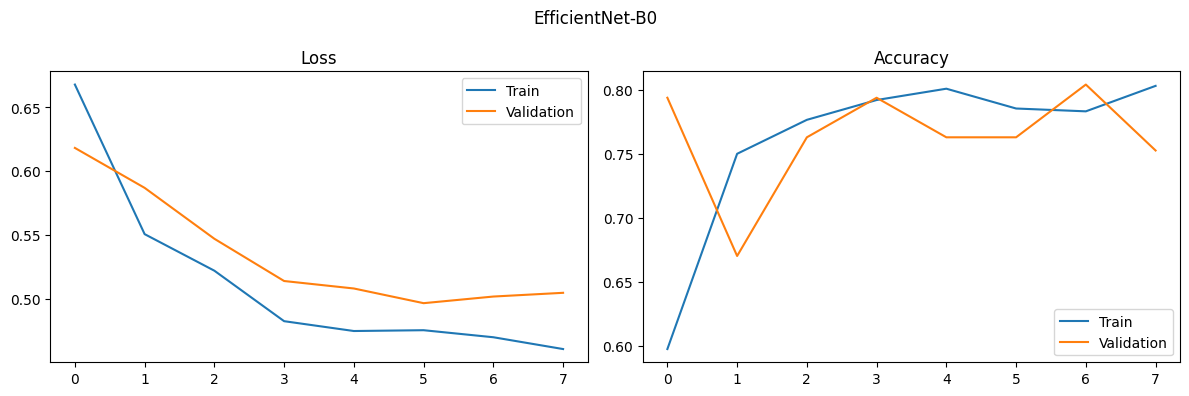

In [14]:
def plot_history(history, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(history["train_loss"], label="Train")
    axes[0].plot(history["val_loss"], label="Validation")
    axes[0].set_title("Loss")
    axes[0].legend()

    axes[1].plot(history["train_acc"], label="Train")
    axes[1].plot(history["val_acc"], label="Validation")
    axes[1].set_title("Accuracy")
    axes[1].legend()

    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

plot_history(hist_cnn, "Custom CNN")
plot_history(hist_resnet, "ResNet-50")
plot_history(hist_eff, "EfficientNet-B0")

In [15]:
for model, name in [
    (resnet, "resnet50_finetuned"),
    (efficientnet, "efficientnet_b0_finetuned")
]:
    for p in model.parameters():
        p.requires_grad = True

    model, history = train_model(
        model, name, epochs=5, lr=1e-5
    )

    if name == "resnet50_finetuned":
        resnet, hist_resnet_ft = model, history
    else:
        efficientnet, hist_eff_ft = model, history

resnet50_finetuned | Epoch 1/5 | Train loss: 0.4696 | Val loss: 0.5166 | Val accuracy: 0.7938
resnet50_finetuned | Epoch 2/5 | Train loss: 0.4352 | Val loss: 0.4854 | Val accuracy: 0.8144
resnet50_finetuned | Epoch 3/5 | Train loss: 0.4329 | Val loss: 0.4778 | Val accuracy: 0.8247
resnet50_finetuned | Epoch 4/5 | Train loss: 0.3991 | Val loss: 0.4473 | Val accuracy: 0.8351
resnet50_finetuned | Epoch 5/5 | Train loss: 0.3705 | Val loss: 0.4598 | Val accuracy: 0.8763
efficientnet_b0_finetuned | Epoch 1/5 | Train loss: 0.4423 | Val loss: 0.4788 | Val accuracy: 0.8041
efficientnet_b0_finetuned | Epoch 2/5 | Train loss: 0.4265 | Val loss: 0.4872 | Val accuracy: 0.8041
efficientnet_b0_finetuned | Epoch 3/5 | Train loss: 0.4100 | Val loss: 0.4504 | Val accuracy: 0.8144
efficientnet_b0_finetuned | Epoch 4/5 | Train loss: 0.4085 | Val loss: 0.4510 | Val accuracy: 0.8041
efficientnet_b0_finetuned | Epoch 5/5 | Train loss: 0.3942 | Val loss: 0.4608 | Val accuracy: 0.8247


Model          Custom CNN
Accuracy          0.56701
Sensitivity      0.806452
Specificity      0.454545
Precision        0.409836
F1               0.543478
ROC_AUC            0.7913
dtype: object

Classification report:
              precision    recall  f1-score   support

      Benign       0.83      0.45      0.59        66
   Malignant       0.41      0.81      0.54        31

    accuracy                           0.57        97
   macro avg       0.62      0.63      0.57        97
weighted avg       0.70      0.57      0.57        97



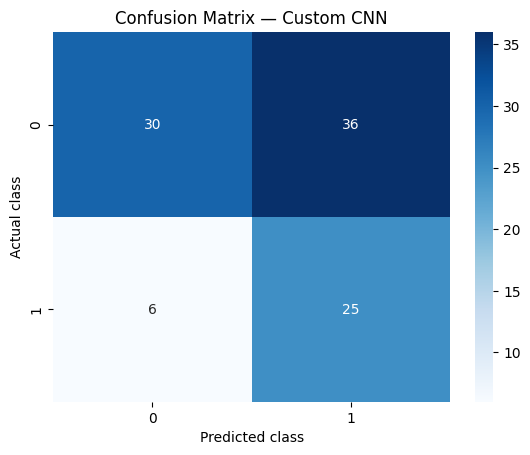

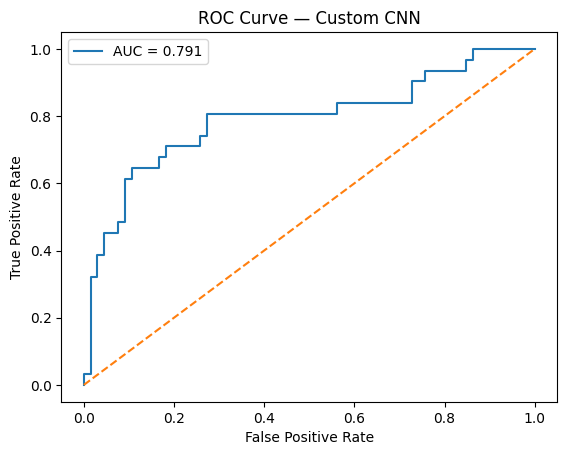

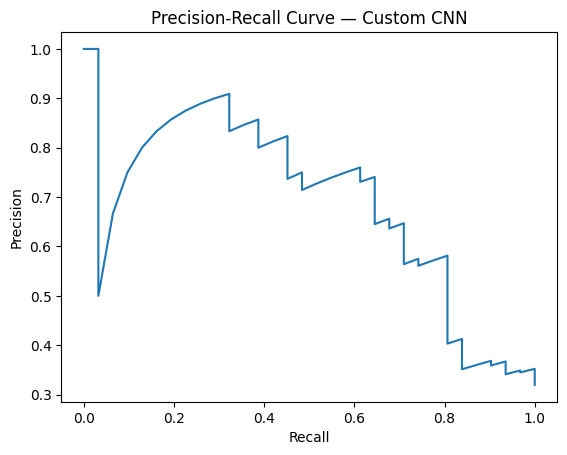

Model          ResNet-50 Fine-tuned
Accuracy                   0.762887
Sensitivity                0.741935
Specificity                0.772727
Precision                  0.605263
F1                         0.666667
ROC_AUC                    0.895406
dtype: object

Classification report:
              precision    recall  f1-score   support

      Benign       0.86      0.77      0.82        66
   Malignant       0.61      0.74      0.67        31

    accuracy                           0.76        97
   macro avg       0.73      0.76      0.74        97
weighted avg       0.78      0.76      0.77        97



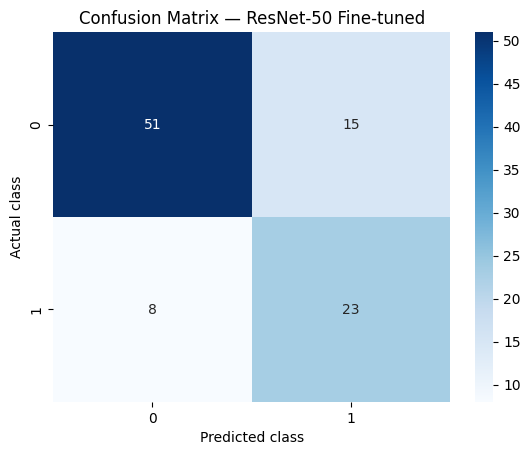

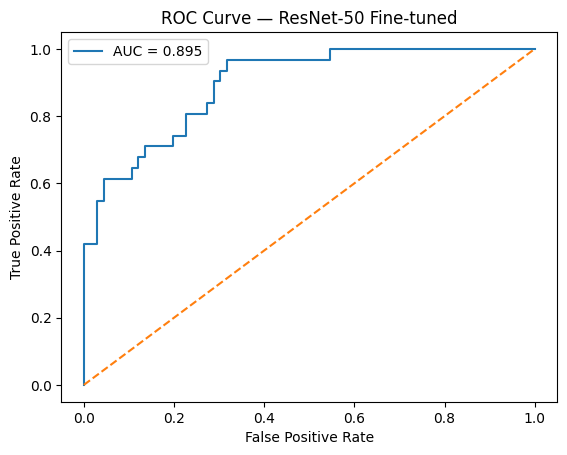

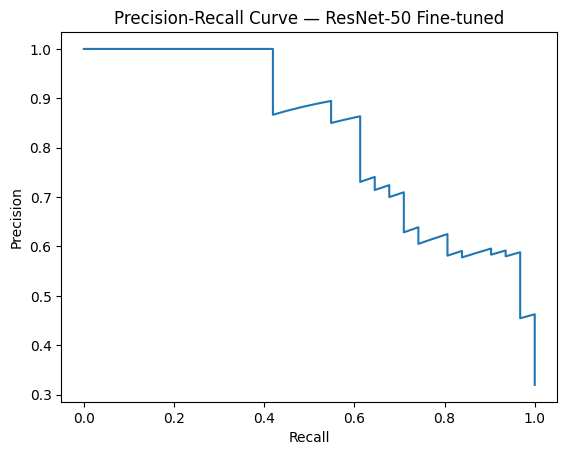

Model          EfficientNet-B0 Fine-tuned
Accuracy                         0.773196
Sensitivity                      0.903226
Specificity                      0.712121
Precision                        0.595745
F1                               0.717949
ROC_AUC                           0.88172
dtype: object

Classification report:
              precision    recall  f1-score   support

      Benign       0.94      0.71      0.81        66
   Malignant       0.60      0.90      0.72        31

    accuracy                           0.77        97
   macro avg       0.77      0.81      0.76        97
weighted avg       0.83      0.77      0.78        97



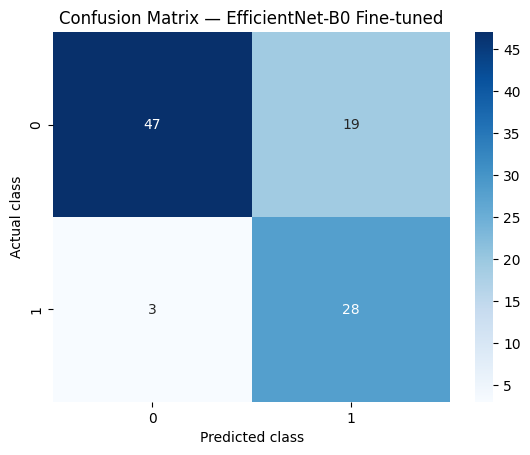

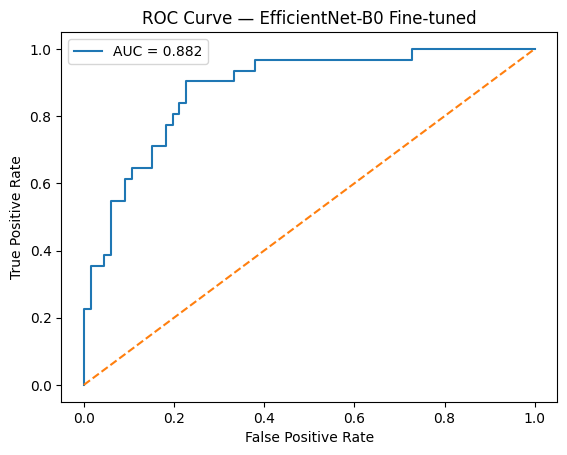

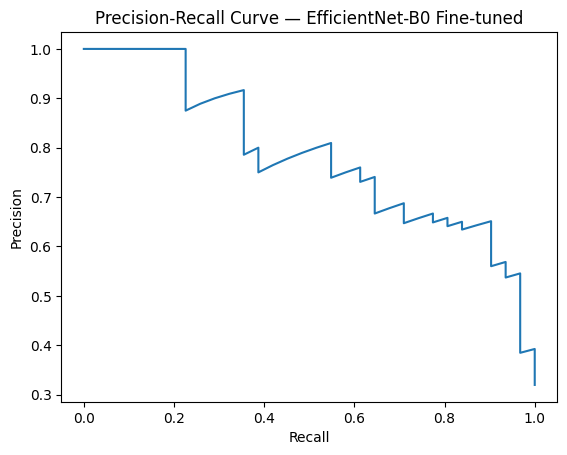

,Model,Accuracy,Sensitivity,Specificity,Precision,F1,ROC_AUC
0,Custom CNN,0.567010,0.806452,0.454545,0.409836,0.543478,0.791300
1,ResNet-50 Fine-tuned,0.762887,0.741935,0.772727,0.605263,0.666667,0.895406
2,EfficientNet-B0 Fine-tuned,0.773196,0.903226,0.712121,0.595745,0.717949,0.881720


In [16]:
def predict_model(model, loader):
    model.eval()
    y_true, y_prob = [], []

    with torch.no_grad():
        for x, y in loader:
            logits = model(x.to(device))
            probs = torch.softmax(logits, dim=1)[:, 1]

            y_true.extend(y.numpy())
            y_prob.extend(probs.cpu().numpy())

    return np.array(y_true), np.array(y_prob)


def evaluate_model(model, name, threshold=0.5):
    y_true, y_prob = predict_model(model, test_loader)
    y_pred = (y_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    results = {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Sensitivity": recall_score(y_true, y_pred, zero_division=0),
        "Specificity": tn / (tn + fp) if tn + fp else 0,
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_true, y_prob)
    }

    print(pd.Series(results))

    print("\nClassification report:")
    print(classification_report(
        y_true, y_pred,
        labels=[0, 1],
        target_names=["Benign", "Malignant"],
        zero_division=0
    ))

    sns.heatmap(
        [[tn, fp], [fn, tp]],
        annot=True, fmt="d", cmap="Blues"
    )
    plt.title(f"Confusion Matrix — {name}")
    plt.xlabel("Predicted class")
    plt.ylabel("Actual class")
    plt.show()

    fpr, tpr, _ = roc_curve(y_true, y_prob)
    plt.plot(fpr, tpr, label=f"AUC = {results['ROC_AUC']:.3f}")
    plt.plot([0, 1], [0, 1], "--")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(f"ROC Curve — {name}")
    plt.legend()
    plt.show()

    precision, recall, _ = precision_recall_curve(y_true, y_prob)
    plt.plot(recall, precision)
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title(f"Precision-Recall Curve — {name}")
    plt.show()

    return results


results = [
    evaluate_model(baseline, "Custom CNN"),
    evaluate_model(resnet, "ResNet-50 Fine-tuned"),
    evaluate_model(efficientnet, "EfficientNet-B0 Fine-tuned")
]

results_df = pd.DataFrame(results)
display(results_df)
results_df.to_csv("classification_results.csv", index=False)

In [17]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Inspect image and mask filename pairs
for label, folder in class_dirs.items():
    print(f"\n--- {label.upper()} ---")

    for path in sorted(folder.glob("*.png"))[:12]:
        print(path.name)


--- BENIGN ---
benign (1).png
benign (1)_mask.png
benign (10).png
benign (10)_mask.png
benign (100).png
benign (100)_mask.png
benign (100)_mask_1.png
benign (101).png
benign (101)_mask.png
benign (102).png
benign (102)_mask.png
benign (103).png

--- MALIGNANT ---
malignant (1).png
malignant (1)_mask.png
malignant (10).png
malignant (10)_mask.png
malignant (100).png
malignant (100)_mask.png
malignant (101).png
malignant (101)_mask.png
malignant (102).png
malignant (102)_mask.png
malignant (103).png
malignant (103)_mask.png

--- NORMAL ---
normal (1).png
normal (1)_mask.png
normal (10).png
normal (10)_mask.png
normal (100).png
normal (100)_mask.png
normal (101).png
normal (101)_mask.png
normal (102).png
normal (102)_mask.png
normal (103).png
normal (103)_mask.png


In [18]:
seg_records = []

for label in ["benign", "malignant"]:
    folder = class_dirs[label]

    for image_path in sorted(folder.glob("*.png")):
        # Exclude masks from the original image list
        if "_mask" in image_path.stem.lower():
            continue

        # Find masks belonging to this image
        mask_paths = sorted(
            image_path.parent.glob(image_path.stem + "_mask*.png")
        )

        if mask_paths:
            seg_records.append({
                "path": str(image_path),
                "label": label,
                "target": 0 if label == "benign" else 1,
                "mask_paths": [str(p) for p in mask_paths]
            })

seg_df = pd.DataFrame(seg_records)

print("Lesion images with masks:", len(seg_df))
print("Benign:", (seg_df["label"] == "benign").sum())
print("Malignant:", (seg_df["label"] == "malignant").sum())

display(seg_df.head())

Lesion images with masks: 647
Benign: 437
Malignant: 210


,path,label,target,mask_paths
0,/root/.cache/kagglehub/datasets/aryashah2k/bre...,benign,0,[/root/.cache/kagglehub/datasets/aryashah2k/br...
1,/root/.cache/kagglehub/datasets/aryashah2k/bre...,benign,0,[/root/.cache/kagglehub/datasets/aryashah2k/br...
2,/root/.cache/kagglehub/datasets/aryashah2k/bre...,benign,0,[/root/.cache/kagglehub/datasets/aryashah2k/br...
3,/root/.cache/kagglehub/datasets/aryashah2k/bre...,benign,0,[/root/.cache/kagglehub/datasets/aryashah2k/br...
4,/root/.cache/kagglehub/datasets/aryashah2k/bre...,benign,0,[/root/.cache/kagglehub/datasets/aryashah2k/br...


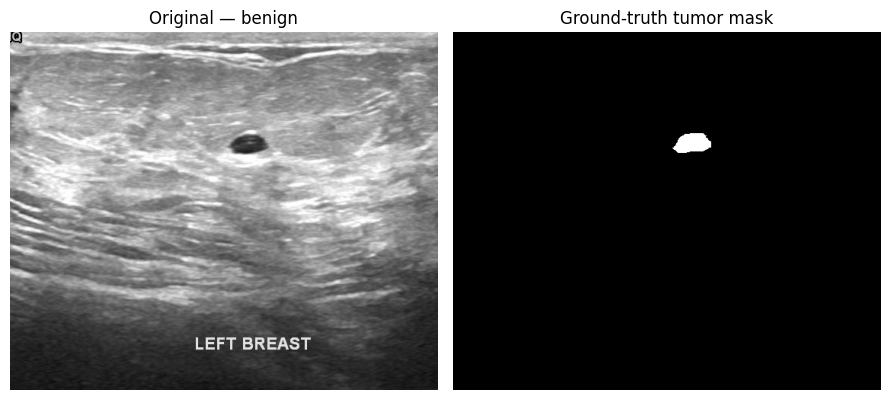

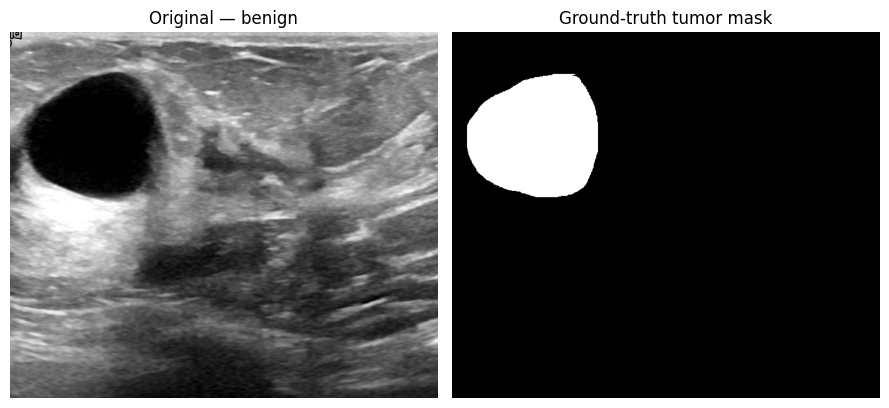

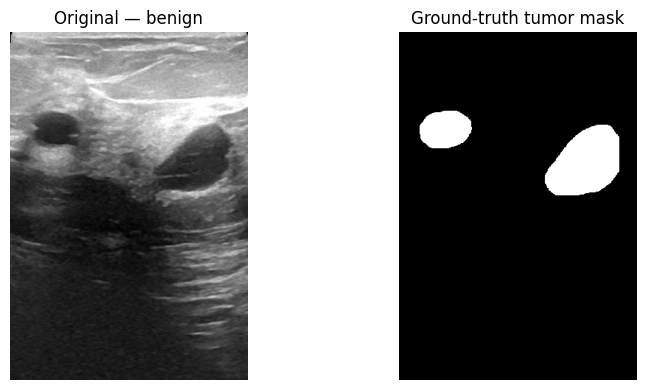

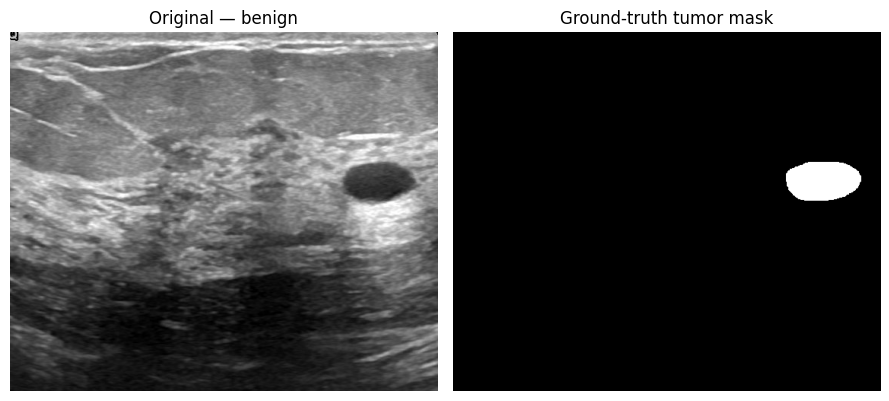

In [19]:
def show_mask_pairs(dataframe, n=4):
    for _, row in dataframe.head(n).iterrows():
        image = Image.open(row["path"]).convert("RGB")

        combined_mask = None

        for mask_path in row["mask_paths"]:
            mask = np.array(
                Image.open(mask_path).convert("L")
            )

            if combined_mask is None:
                combined_mask = mask
            else:
                combined_mask = np.maximum(combined_mask, mask)

        fig, axes = plt.subplots(1, 2, figsize=(9, 4))

        axes[0].imshow(image)
        axes[0].set_title(f"Original — {row['label']}")

        axes[1].imshow(combined_mask, cmap="gray")
        axes[1].set_title("Ground-truth tumor mask")

        for ax in axes:
            ax.axis("off")

        plt.tight_layout()
        plt.show()

show_mask_pairs(seg_df, n=4)

In [20]:
import torch
from torch.utils.data import Dataset, DataLoader

class BreastSegmentationDataset(Dataset):
    def __init__(self, dataframe, augment=False):
        self.df = dataframe.reset_index(drop=True)
        self.augment = augment

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        image = Image.open(row["path"]).convert("RGB")
        image = image.resize((224, 224), Image.Resampling.BILINEAR)

        combined_mask = None

        for mask_path in row["mask_paths"]:
            mask = Image.open(mask_path).convert("L")
            mask = mask.resize(
                (224, 224), Image.Resampling.NEAREST
            )
            mask_array = np.array(mask)

            if combined_mask is None:
                combined_mask = mask_array
            else:
                combined_mask = np.maximum(
                    combined_mask, mask_array
                )

        image = np.array(image).copy()
        combined_mask = (combined_mask > 0).astype(np.float32)

        # Apply the same spatial augmentation to image and mask
        if self.augment and random.random() < 0.5:
            image = np.fliplr(image).copy()
            combined_mask = np.fliplr(combined_mask).copy()

        image = torch.from_numpy(image).permute(2, 0, 1).float() / 255.0

        mask = torch.from_numpy(
            combined_mask.copy()
        ).unsqueeze(0)

        # ImageNet normalization for the image only
        mean = torch.tensor(
            [0.485, 0.456, 0.406]
        ).view(3, 1, 1)

        std = torch.tensor(
            [0.229, 0.224, 0.225]
        ).view(3, 1, 1)

        image = (image - mean) / std

        return image, mask

In [21]:
seg_train_df, seg_temp_df = train_test_split(
    seg_df,
    test_size=0.30,
    random_state=42,
    stratify=seg_df["label"]
)

seg_val_df, seg_test_df = train_test_split(
    seg_temp_df,
    test_size=0.50,
    random_state=42,
    stratify=seg_temp_df["label"]
)

seg_train_loader = DataLoader(
    BreastSegmentationDataset(seg_train_df, augment=True),
    batch_size=8,
    shuffle=True,
    num_workers=2
)

seg_val_loader = DataLoader(
    BreastSegmentationDataset(seg_val_df),
    batch_size=8,
    shuffle=False,
    num_workers=2
)

seg_test_loader = DataLoader(
    BreastSegmentationDataset(seg_test_df),
    batch_size=8,
    shuffle=False,
    num_workers=2
)

images, masks = next(iter(seg_train_loader))

print("Images:", images.shape)
print("Masks:", masks.shape)

Images: torch.Size([8, 3, 224, 224])
Masks: torch.Size([8, 1, 224, 224])


In [22]:
class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(out_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class UNet(nn.Module):
    def __init__(self):
        super().__init__()

        self.pool = nn.MaxPool2d(2)

        self.enc1 = ConvBlock(3, 32)
        self.enc2 = ConvBlock(32, 64)
        self.enc3 = ConvBlock(64, 128)

        self.bottleneck = ConvBlock(128, 256)

        self.up3 = nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.dec3 = ConvBlock(256, 128)

        self.up2 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.dec2 = ConvBlock(128, 64)

        self.up1 = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.dec1 = ConvBlock(64, 32)

        self.output = nn.Conv2d(32, 1, kernel_size=1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))

        b = self.bottleneck(self.pool(e3))

        d3 = self.dec3(
            torch.cat([self.up3(b), e3], dim=1)
        )

        d2 = self.dec2(
            torch.cat([self.up2(d3), e2], dim=1)
        )

        d1 = self.dec1(
            torch.cat([self.up1(d2), e1], dim=1)
        )

        # Raw logits; sigmoid is applied during evaluation
        return self.output(d1)


unet = UNet().to(device)

print("U-Net created on:", device)

U-Net created on: cpu


In [23]:
def dice_loss(logits, targets, eps=1e-6):
    probabilities = torch.sigmoid(logits)

    intersection = (
        probabilities * targets
    ).sum(dim=(1, 2, 3))

    denominator = (
        probabilities.sum(dim=(1, 2, 3))
        + targets.sum(dim=(1, 2, 3))
    )

    dice = (2 * intersection + eps) / (denominator + eps)

    return 1 - dice.mean()


def segmentation_loss(logits, targets):
    bce = nn.functional.binary_cross_entropy_with_logits(
        logits, targets
    )

    return bce + dice_loss(logits, targets)


optimizer = torch.optim.AdamW(
    unet.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)


def run_segmentation_epoch(loader, training):
    unet.train(training)

    total_loss = 0.0
    total_images = 0

    for images, masks in loader:
        images = images.to(device)
        masks = masks.to(device)

        if training:
            optimizer.zero_grad()

        with torch.set_grad_enabled(training):
            logits = unet(images)
            loss = segmentation_loss(logits, masks)

            if training:
                loss.backward()
                optimizer.step()

        total_loss += loss.item() * images.size(0)
        total_images += images.size(0)

    return total_loss / total_images


seg_history = {
    "train_loss": [],
    "val_loss": []
}

best_val_loss = float("inf")

for epoch in range(10):
    train_loss = run_segmentation_epoch(
        seg_train_loader, training=True
    )

    val_loss = run_segmentation_epoch(
        seg_val_loader, training=False
    )

    seg_history["train_loss"].append(train_loss)
    seg_history["val_loss"].append(val_loss)

    print(
        f"Epoch {epoch + 1}/10 | "
        f"Train loss: {train_loss:.4f} | "
        f"Validation loss: {val_loss:.4f}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(unet.state_dict(), "unet_best.pth")

unet.load_state_dict(
    torch.load(
        "unet_best.pth",
        map_location=device,
        weights_only=True
    )
)

Epoch 1/10 | Train loss: 1.3017 | Validation loss: 2.4773
Epoch 2/10 | Train loss: 1.0873 | Validation loss: 1.3243
Epoch 3/10 | Train loss: 0.9638 | Validation loss: 0.9915
Epoch 4/10 | Train loss: 0.8868 | Validation loss: 2.2358
Epoch 5/10 | Train loss: 0.8250 | Validation loss: 0.9308
Epoch 6/10 | Train loss: 0.7740 | Validation loss: 0.8500
Epoch 7/10 | Train loss: 0.7420 | Validation loss: 0.8474
Epoch 8/10 | Train loss: 0.7226 | Validation loss: 0.6499
Epoch 9/10 | Train loss: 0.7126 | Validation loss: 0.7061
Epoch 10/10 | Train loss: 0.7043 | Validation loss: 0.7089


<All keys matched successfully>

In [24]:
def evaluate_segmentation(model, loader, threshold=0.5, eps=1e-7):
    model.eval()

    dice_scores = []
    iou_scores = []

    with torch.no_grad():
        for images, masks in loader:
            images = images.to(device)
            masks = masks.to(device)

            probabilities = torch.sigmoid(model(images))
            predictions = (probabilities >= threshold).float()

            intersection = (
                predictions * masks
            ).sum(dim=(1, 2, 3))

            union = (
                (predictions + masks) > 0
            ).float().sum(dim=(1, 2, 3))

            total = (
                predictions.sum(dim=(1, 2, 3))
                + masks.sum(dim=(1, 2, 3))
            )

            dice = (2 * intersection + eps) / (total + eps)
            iou = (intersection + eps) / (union + eps)

            dice_scores.extend(dice.cpu().tolist())
            iou_scores.extend(iou.cpu().tolist())

    print(f"Test Dice: {np.mean(dice_scores):.4f}")
    print(f"Test IoU:  {np.mean(iou_scores):.4f}")

    return np.mean(dice_scores), np.mean(iou_scores)


test_dice, test_iou = evaluate_segmentation(
    unet, seg_test_loader
)

Test Dice: 0.5636
Test IoU:  0.4556


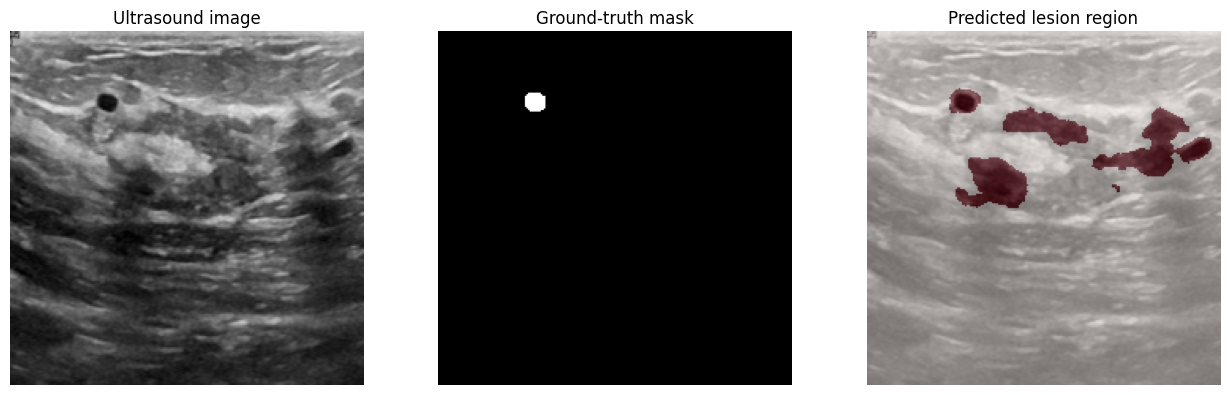

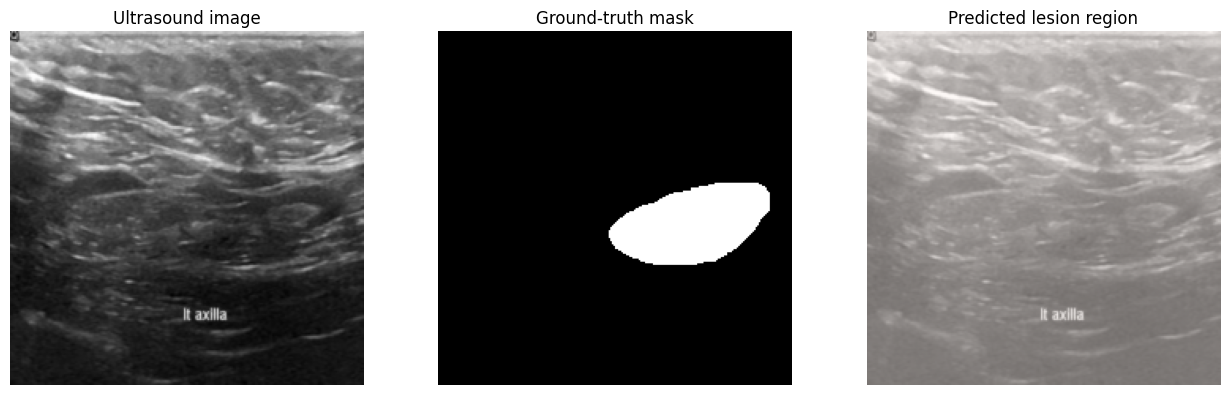

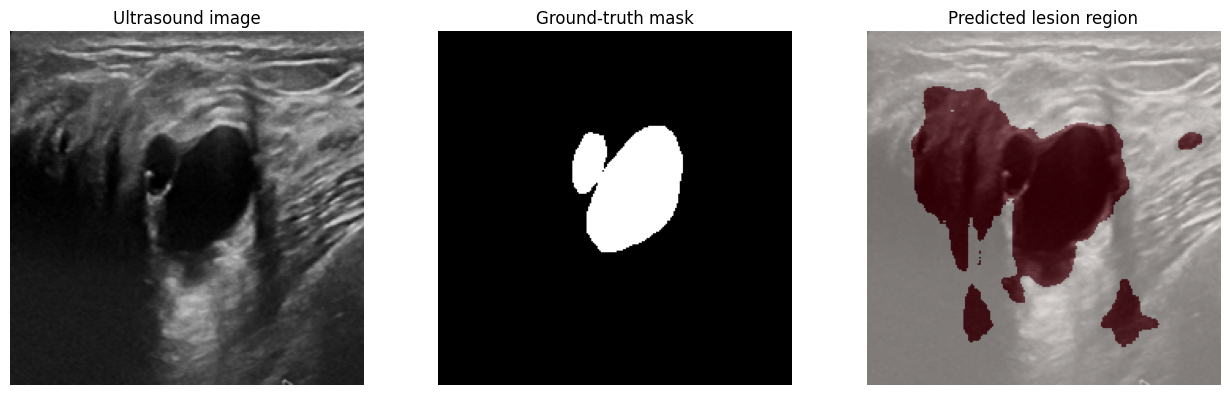

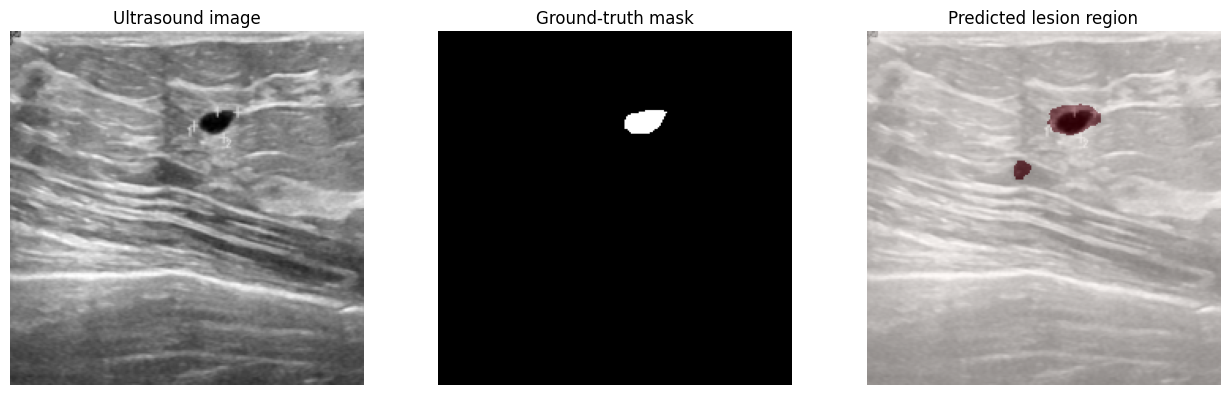

In [25]:
def show_segmentation_predictions(model, dataset, n=4):
    model.eval()

    mean = torch.tensor(
        [0.485, 0.456, 0.406]
    ).view(3, 1, 1)

    std = torch.tensor(
        [0.229, 0.224, 0.225]
    ).view(3, 1, 1)

    for idx in range(min(n, len(dataset))):
        image, mask = dataset[idx]

        with torch.no_grad():
            logits = model(image.unsqueeze(0).to(device))
            prediction = (
                torch.sigmoid(logits)[0, 0].cpu().numpy() >= 0.5
            )

        original = (image * std + mean).clamp(0, 1)
        original = original.permute(1, 2, 0).numpy()

        fig, axes = plt.subplots(1, 3, figsize=(13, 4))

        axes[0].imshow(original)
        axes[0].set_title("Ultrasound image")

        axes[1].imshow(mask[0], cmap="gray")
        axes[1].set_title("Ground-truth mask")

        axes[2].imshow(original)
        axes[2].imshow(
            prediction,
            cmap="Reds",
            alpha=0.45,
            vmin=0,
            vmax=1
        )
        axes[2].set_title("Predicted lesion region")

        for ax in axes:
            ax.axis("off")

        plt.tight_layout()
        plt.show()


show_segmentation_predictions(
    unet,
    BreastSegmentationDataset(seg_test_df),
    n=4
)

In [26]:
import os

os.makedirs("results", exist_ok=True)
os.makedirs("models", exist_ok=True)

results_df.to_csv(
    "results/classification_results.csv",
    index=False
)

pd.DataFrame([{
    "Model": "U-Net",
    "Dice": test_dice,
    "IoU": test_iou
}]).to_csv(
    "results/segmentation_results.csv",
    index=False
)

torch.save(
    unet.state_dict(),
    "models/unet_best.pth"
)

print("Results and U-Net model saved.")

Results and U-Net model saved.


In [27]:
# Final classification comparison
final_classification = results_df.copy()

display(
    final_classification.style.format({
        "Accuracy": "{:.4f}",
        "Sensitivity": "{:.4f}",
        "Specificity": "{:.4f}",
        "Precision": "{:.4f}",
        "F1": "{:.4f}",
        "ROC_AUC": "{:.4f}"
    })
)

# Final segmentation results
final_segmentation = pd.DataFrame([{
    "Model": "U-Net",
    "Dice": test_dice,
    "IoU": test_iou
}])

display(final_segmentation.style.format({
    "Dice": "{:.4f}",
    "IoU": "{:.4f}"
}))

# Save both tables
final_classification.to_csv(
    "classification_results.csv", index=False
)

final_segmentation.to_csv(
    "segmentation_results.csv", index=False
)

print("Final results tables generated successfully.")

,Model,Accuracy,Sensitivity,Specificity,Precision,F1,ROC_AUC
0,Custom CNN,0.5670,0.8065,0.4545,0.4098,0.5435,0.7913
1,ResNet-50 Fine-tuned,0.7629,0.7419,0.7727,0.6053,0.6667,0.8954
2,EfficientNet-B0 Fine-tuned,0.7732,0.9032,0.7121,0.5957,0.7179,0.8817


,Model,Dice,IoU
0,U-Net,0.5636,0.4556


Final results tables generated successfully.
